In [7]:
import numpy  as  np
import pandas  as  pd
import matplotlib.pyplot  as  plt
import japanize_matplotlib
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import f1_score

print("-Irisのデータ列の統計的な情報およ相関係数を求め・表示-")
# ==================================================
# Irisデータセットについて　振り返りよう補足
# ==================================================
#
# X（特徴量）: アヤメの花の計測データ 150件 × 4列
#
#   SepalLength : がく片の長さ
#   SepalWidth  : がく片の幅
#   PetalLength : 花びらの長さ
#   PetalWidth  : 花びらの幅
#
# --------------------------------------------------
#
# y（教師信号）: 各データが「何の種類か」を示す正解ラベル
#
#   0 → setosa     （アヤメの種類①）
#   1 → versicolor （アヤメの種類②）
#   2 → virginica  （アヤメの種類③）
#
# --------------------------------------------------
#
# XとYの関係：
#   「この4つの数値の組み合わせ（X）は、この種類（y）だよ」
#   という対応表。
#   SVMはこの対応を150件分学習し、
#   新しいデータが来たとき種類を予測する。
#
# ==================================================


# ★★★Irisデータ★★★
iris0 = load_iris( )
X = pd.DataFrame( iris0.data )
y = iris0.target
Target_Name = iris0.target_names
Feature_Names = ["SepalLength","SepalWidth","PetalLength","PetalWidth"]
X.columns =  Feature_Names              
display(X.head())
print("y=",y[0:5])


-Irisのデータ列の統計的な情報およ相関係数を求め・表示-


,SepalLength,SepalWidth,PetalLength,PetalWidth
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


y= [0 0 0 0 0]


統計情報

       SepalLength  SepalWidth  PetalLength  PetalWidth
count   150.000000  150.000000   150.000000  150.000000
mean      5.843333    3.057333     3.758000    1.199333
std       0.828066    0.435866     1.765298    0.762238
min       4.300000    2.000000     1.000000    0.100000
25%       5.100000    2.800000     1.600000    0.300000
50%       5.800000    3.000000     4.350000    1.300000
75%       6.400000    3.300000     5.100000    1.800000
max       7.900000    4.400000     6.900000    2.500000

相関係数(共分散)

             SepalLength  SepalWidth  PetalLength  PetalWidth
SepalLength     1.000000   -0.117570     0.871754    0.817941
SepalWidth     -0.117570    1.000000    -0.428440   -0.366126
PetalLength     0.871754   -0.428440     1.000000    0.962865
PetalWidth      0.817941   -0.366126     0.962865    1.000000

共分散行列

             SepalLength  SepalWidth  PetalLength  PetalWidth
SepalLength     0.685694   -0.042434     1.274315    0.516271
SepalWidth     -0.042434    0.189979

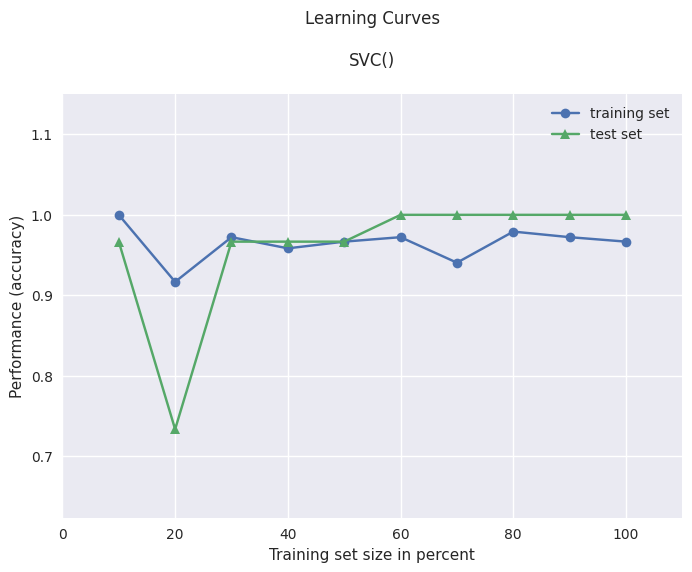

In [9]:

X.columns = ["SepalLength","SepalWidth","PetalLength","PetalWidth"]
y=iris0.target

print( "統計情報" )
print()
print( X.describe( ) )

print()
print( "相関係数(共分散)" )
print()
print( X.corr() )

print()
print("共分散行列")
print()
print( X.cov() )

#train_0.8 test_0.2
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)
obj = SVC()
obj.fit(X_train, y_train)

# ★★★可視化★★★
print("--------------学習曲線-------------------")
from mlxtend.plotting import plot_learning_curves
plot_learning_curves( X_train, y_train, X_test, y_test,
obj,
train_marker = 'o',
test_marker = '^',
style = 'seaborn-v0_8',
scoring = 'accuracy' )
plt.show()


In [13]:

#サポートベクターマシン(svm.SVC)で分類

# ★★★学習モデル★★★
obj=SVC()
obj.fit( X_train, y_train )
pred = obj.predict( X_test )
plot_learning_curves( X_train, y_train, X_test, y_test,obj)
# ★★★評価★★★
print("評価:SVC,accuracy=",obj.score(X_test, y_test))



評価:SVC,accuracy= 1.0


真値  == [1 0 1 1 2 0 2 0 2 2 2 1 2 1 1 1 0 0 0 0 0 1 2 1 0 0 1 1 2 2]
予測値== [1 0 1 1 2 0 2 0 2 2 2 1 2 1 1 1 0 0 0 0 0 1 2 1 0 0 1 1 2 2]
[[10  0  0]
 [ 0 11  0]
 [ 0  0  9]]


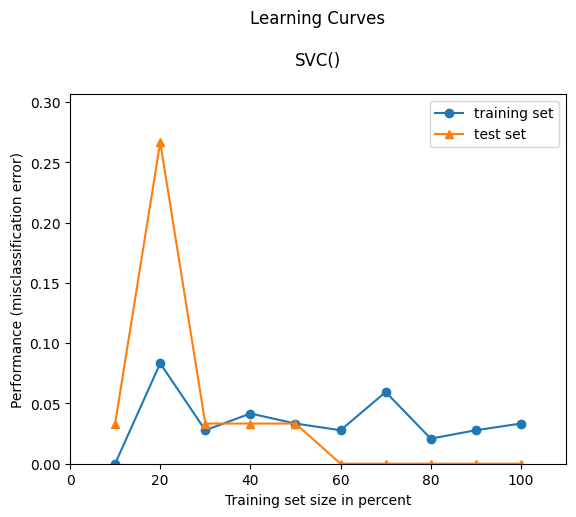

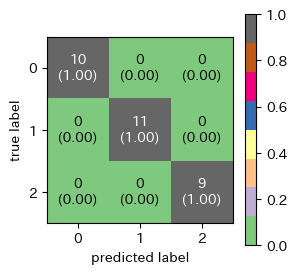

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00        11
           2       1.00      1.00      1.00         9

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



In [14]:
from sklearn.metrics import confusion_matrix
from mlxtend.plotting import plot_confusion_matrix
print("真値  ==", y_test)
print("予測値==", pred)

Conf_Matrix = confusion_matrix(y_test, pred)
print(Conf_Matrix)

fig, ax = plot_confusion_matrix( conf_mat=Conf_Matrix,
          figsize=(3, 3),     show_absolute=True,     show_normed=True,
         colorbar=True,  cmap='Accent',      )
plt.show()



# 評価指標 : 正解率(Accuracy)・適合率(precision)  再現率(recall)・F 値
from sklearn.metrics   import classification_report
ret = classification_report(y_test, pred,)
print(ret)

# ==================================================
# 評価指標の説明　　振り返りよう補足
# ==================================================
#
# 【Accuracy（正解率）】
#   全データのうち正しく予測できた割合
#   例）30問中27問正解 → 0.90
#
# 【Precision（適合率）】
#   「この種類だ」と予測した中で、本当にそうだった割合
#   → 「外れ予測を出さない」能力
#
# 【Recall（再現率）】
#   本当にその種類のデータを、正しく拾えた割合
#   → 「見逃さない」能力
#
# 【F1-score】
#   PrecisionとRecallの調和平均
#   → 2つのバランスを1つの数値で表したもの
#
# 【support】
#   そのクラスの実際のデータ件数
#
# --------------------------------------------------
#
# ※ Accuracyだけでは不十分な理由：
#   データが偏っている場合（例：90%がclass0）、
#   全部class0と予測するだけでAccuracy=90%になってしまう。
#   → Precision・Recall・F1も合わせて確認することが重要。
#
# ==================================================

評価:SVC,accuracy= 0.9333333333333333
--------------学習曲線-------------------


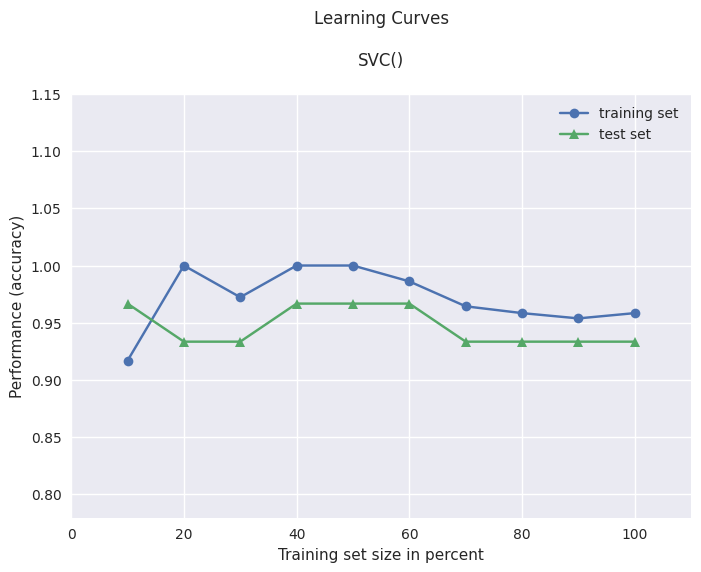

----------------決定境界--------------------


/Applications/anaconda3/envs/python-myenv/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


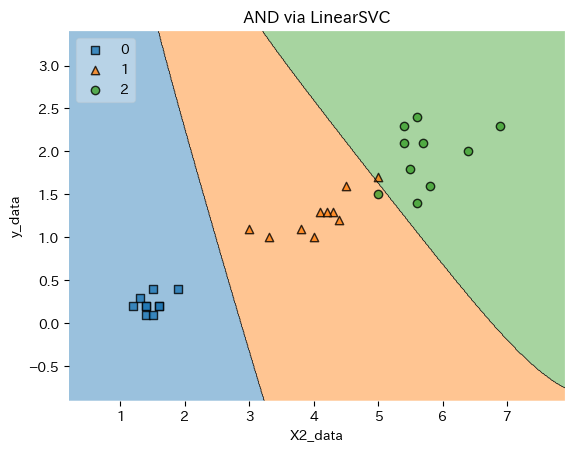

In [16]:
# ==================================================
# 2特徴量に絞ってSVMを再実行する理由
# ==================================================
#
# 【なぜ4つから2つに絞るのか】
#
#   ① 決定境界を可視化するため
#      4特徴量 → 4次元 → 図に描けない
#      2特徴量 → 2次元 → 平面に描ける
#
#   ② 重要な特徴量だけで十分か確認するため
#      相関係数より PetalLength と PetalWidth は
#      相関が高い（≒0.96）
#      → この2つだけでも分類できるか検証する
#
# --------------------------------------------------

# ★★★Irisデータ★★★
X2 = X[["PetalLength","PetalWidth"]]
y=iris0.target

#       サポートベクターマシン(svm.SVC)で分類問題
X2_train, X2_test, y_train, y_test = train_test_split( X2, y, test_size=0.2 )
# ★★★学習モデル★★★
obj2=SVC()
obj2.fit( X2_train, y_train )
pred = obj2.predict( X2_test )

# ★★★評価★★★
print("評価:SVC,accuracy=",obj2.score(X2_test, y_test))

# ★★★可視化★★★
print("--------------学習曲線-------------------")
from mlxtend.plotting import plot_learning_curves
plot_learning_curves( X2_train, y_train, X2_test, y_test,
obj2,
train_marker = 'o',
test_marker = '^',
style = 'seaborn-v0_8',
scoring = 'accuracy' )
plt.show()

print("----------------決定境界--------------------")
from mlxtend.plotting import plot_decision_regions
X2_test = np.array(X2_test)
y_test = np.array(y_test)

plot_decision_regions(X2_test, y_test, clf=obj2, legend=2)
plt.xlabel('X2_data')
plt.ylabel('y_data')
plt.title(' AND via LinearSVC ')
plt.show()


## 考察

### 4特徴量 vs 2特徴量の比較
- 4特徴量のaccuracy : 1.0
- 2特徴量のaccuracy : 0.93
- PetalLengthとPetalWidthの2つだけでも十分な精度が出た

### 決定境界から読み取れること
- class0は他と明確に分離できている
- class1とclass2の境界は複雑になっている
